In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error

root = Path.home() / "Desktop/Chooser_Option_Research"

dataset = pd.read_csv(
    root / "02_Data/processed/W06_Synthetic_Heston_Dataset.csv"
)

features = [
    "moneyness", "T1", "T2",
    "r1", "r2", "q",
    "v0", "theta", "kappa", "xi", "rho"
]

train = dataset[dataset["split"] == "train"].copy()
valid = dataset[dataset["split"] == "validation"].copy()
test = dataset[dataset["split"] == "test"].copy()

models = {
    "RF Direct": RandomForestRegressor(
        n_estimators=350,
        min_samples_leaf=2,
        max_features=0.85,
        random_state=42,
        n_jobs=-1
    ),
    "RF Correction": RandomForestRegressor(
        n_estimators=350,
        min_samples_leaf=2,
        max_features=0.85,
        random_state=42,
        n_jobs=-1
    ),
    "HGB Correction": HistGradientBoostingRegressor(
        max_iter=350,
        max_leaf_nodes=15,
        learning_rate=0.05,
        l2_regularization=0.1,
        random_state=42
    )
}

def predict_price(name, model, frame):
    predicted = model.predict(frame[features])
    predicted = predicted * frame["S"].to_numpy()

    if name != "RF Direct":
        predicted += frame["bsm_price"].to_numpy()

    return predicted

def evaluate(actual, predicted):
    return {
        "MAE (USD/share)": mean_absolute_error(actual, predicted),
        "RMSE (USD/share)": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }

validation_rows = []

for name, model in models.items():

    target = (
        "target_price_norm"
        if name == "RF Direct"
        else "target_delta_norm"
    )

    model.fit(train[features], train[target])

    predictions = predict_price(name, model, valid)

    validation_rows.append({
        "Model": name,
        **evaluate(valid["heston_price"], predictions)
    })

validation_rows.append({
    "Model": "BSM Baseline",
    **evaluate(valid["heston_price"], valid["bsm_price"])
})

validation_df = pd.DataFrame(validation_rows)

display(
    validation_df.sort_values(
        "MAE (USD/share)"
    ).round(4)
)

# Select ML model using validation only
ml_validation = validation_df[
    validation_df["Model"] != "BSM Baseline"
]

best_name = ml_validation.sort_values(
    "MAE (USD/share)"
).iloc[0]["Model"]

best_model = models[best_name]

print("Validation-selected ML model:", best_name)

,Model,MAE (USD/share),RMSE (USD/share)
2,HGB Correction,0.9124,1.1631
1,RF Correction,1.1285,1.4790
0,RF Direct,2.5929,3.3284
3,BSM Baseline,3.8187,4.9564


Validation-selected ML model: HGB Correction


,Model,MAE (USD/share),RMSE (USD/share)
2,HGB Correction,1.0320,1.4625
1,RF Correction,1.3017,1.7803
0,RF Direct,2.2763,3.1232
3,BSM Baseline,4.4915,5.9454


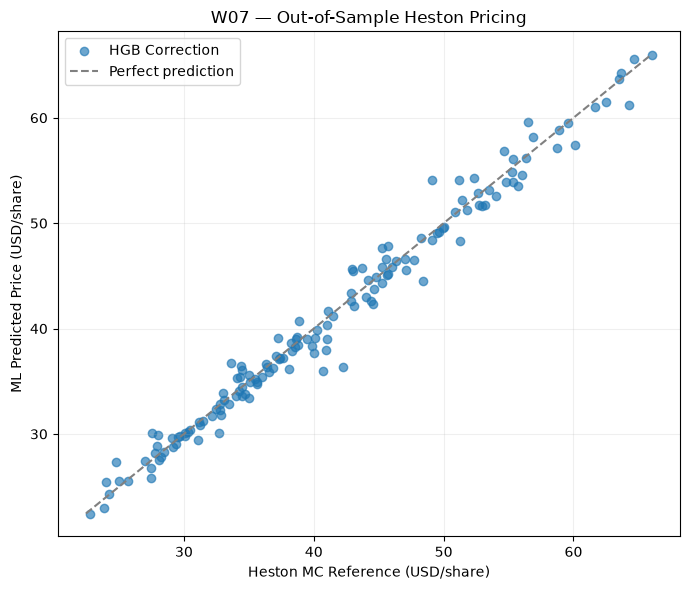

In [2]:
import matplotlib.pyplot as plt
import joblib

test_rows = []

for name, model in models.items():
    pred = predict_price(name, model, test)

    test_rows.append({
        "Model": name,
        **evaluate(test["heston_price"], pred)
    })

test_rows.append({
    "Model": "BSM Baseline",
    **evaluate(test["heston_price"], test["bsm_price"])
})

test_df = pd.DataFrame(test_rows)

display(
    test_df.sort_values("MAE (USD/share)").round(4)
)

selected_pred = predict_price(best_name, best_model, test)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    test["heston_price"],
    selected_pred,
    alpha=0.65,
    label=best_name
)

bounds_plot = [
    min(test["heston_price"].min(), selected_pred.min()),
    max(test["heston_price"].max(), selected_pred.max())
]

ax.plot(
    bounds_plot, bounds_plot,
    "--", color="gray", label="Perfect prediction"
)

ax.set_xlabel("Heston MC Reference (USD/share)")
ax.set_ylabel("ML Predicted Price (USD/share)")
ax.set_title("W07 — Out-of-Sample Heston Pricing")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

fig_dir = root / "04_Reports/weekly/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    fig_dir / "W07_Predicted_vs_Heston.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save trained model for W08
model_dir = root / "03_Code/models"
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "name": best_name,
        "model": best_model,
        "features": features
    },
    model_dir / "W07_Selected_Pricing_Model.joblib"
)

test_df.to_csv(
    root / "02_Data/processed/W07_Model_Comparison.csv",
    index=False
)